# Домашнє завдання: Прогнозування кредитного ризику

## Мета завдання
Застосувати знання з лекції для побудови моделі логістичної регресії, що прогнозує ймовірність дефолту за кредитом, іншими словами, що людина не поверне кредит. Ви пройдете весь цикл: від дослідницького аналізу до оцінки якості класифікаційної моделі.

## Опис датасету
**Credit Risk Dataset** містить інформацію про 32,000+ позичальників з такими параметрами:
- **person_age**: Вік позичальника
- **person_income**: Річний дохід
- **person_home_ownership**: Тип володіння житлом
- **person_emp_length**: Стаж роботи (в роках)
- **loan_intent**: Мета кредиту
- **loan_grade**: Кредитний рейтинг (A - кращий, F - гірший)
- **loan_amnt**: Сума кредиту
- **loan_int_rate**: Процентна ставка
- **loan_status**: Статус кредиту (0 = сплачено, 1 = дефолт) - **цільова змінна**
- **loan_percent_income**: Відношення кредиту до доходу
- **cb_person_default_on_file**: Історія дефолтів (Y/N)
- **cb_person_cred_hist_length**: Довжина кредитної історії

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `credit_risk_dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (кількість записів, типи колонок)
5. Перевірте розподіл цільової змінної (відсотк даних для кожного класу)

Дайте висновок, це задача збалансованої чи незбалансованої класифікації.


In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

df = pd.read_csv('credit_risk_dataset.csv')

print(f'Розмір датасету: {df.shape[0]} рядків, {df.shape[1]} колонок')

Розмір датасету: 32581 рядків, 12 колонок


In [2]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [4]:
pd.DataFrame({
    'Кількість': df['loan_status'].value_counts(),
    'Відсоток, %': (df['loan_status'].value_counts(normalize=True) * 100).round(2),
}).rename(index={0: '0 — кредит сплачено', 1: '1 — дефолт'})

,Кількість,"Відсоток, %"
loan_status,,
0 — кредит сплачено,25473,78.18
1 — дефолт,7108,21.82


**Висновок.** У датасеті 32 581 позичальник і 12 колонок: 8 числових і 4 текстові (`person_home_ownership`, `loan_intent`, `loan_grade`, `cb_person_default_on_file`). У `person_emp_length` і `loan_int_rate` непорожніх значень менше, ніж рядків, — там є пропуски.

Дефолтів — 21.8 %, сплачених кредитів — 78.2 % (приблизно 1 до 3.6). Це задача **незбалансованої класифікації**. Тому:
- accuracy вводить в оману: модель, яка завжди каже «сплатить», уже має 78 % accuracy;
- оцінюємо модель через precision, recall, F1 і ROC AUC;
- ділимо дані на train і test зі стратифікацією, щоб частка дефолтів в обох була однакова.


---

## Завдання 2: Дослідницький аналіз даних (EDA) (4 бали)

**Що потрібно зробити:**
1. Обчисліть відсоток пропущених значень в колонках. За наявності пропущених значень - заповніть їх медіаною для числових колонок і найбільш частим значеннмя для категоріальних.
2. Проаналізуйте розподіл числових змінних.
3. Знайдіть та обробіть викиди в колонці person_income з допомогою [Interquartile range](https://uk.wikipedia.org/wiki/%D0%9C%D1%96%D0%B6%D0%BA%D0%B2%D0%B0%D1%80%D1%82%D0%B8%D0%BB%D1%8C%D0%BD%D0%B8%D0%B9_%D1%80%D0%BE%D0%B7%D0%BC%D0%B0%D1%85).
4. Проаналізуйте категоріальні змінні відносно цільової та частоту зустрічання різних значень в них.
5. Візуалізуйте взаємозв'язок ознак з цільовою змінною.


In [5]:
missing_pct = (df.isnull().mean() * 100).round(2)
print('Пропуски, %:')
print(missing_pct[missing_pct > 0])

num_cols = df.select_dtypes('number').columns.drop('loan_status')
cat_cols = df.select_dtypes('object').columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print('\nПропусків після заповнення:', df.isnull().sum().sum())

Пропуски, %:
person_emp_length    2.75
loan_int_rate        9.56
dtype: float64

Пропусків після заповнення: 0


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,32581.00,32581.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.77,9589.37,11.01,0.17,5.80
std,6.35,61983.12,4.09,6322.09,3.08,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,8.49,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.11,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,0.83,30.00


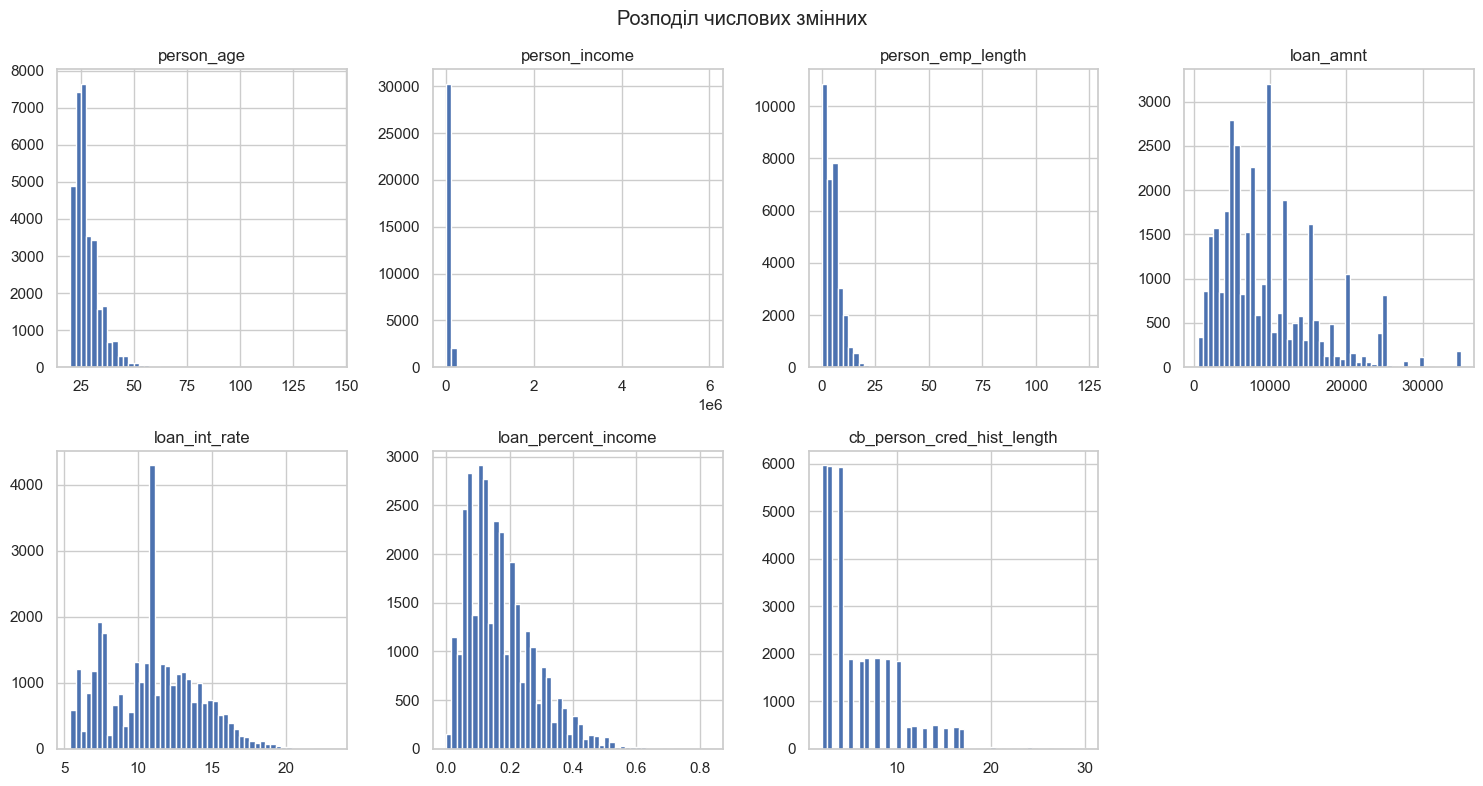

In [6]:
display(df[num_cols].describe().round(2))

df[num_cols].hist(bins=50, figsize=(15, 8), layout=(2, 4))
plt.suptitle('Розподіл числових змінних')
plt.tight_layout()
plt.show()

In [7]:
print('Вік понад 100 років:', (df['person_age'] > 100).sum())
print('Стаж понад 60 років:', (df['person_emp_length'] > 60).sum())
print('Повних дублікатів:', df.duplicated().sum())

df = df[(df['person_age'] <= 100) & (df['person_emp_length'] <= 60)].drop_duplicates().copy()
print(f'Після очищення: {len(df)} рядків')

Вік понад 100 років: 5
Стаж понад 60 років: 2
Повних дублікатів: 165
Після очищення: 32409 рядків


Q1 = 38,500, Q3 = 79,200, IQR = 40,700
Межі: від -22,550 до 140,250
Викидів: 1474 (4.5%), максимальний дохід: 2,039,784
Частка дефолтів серед викидів: 9.8%, серед решти: 22.4%


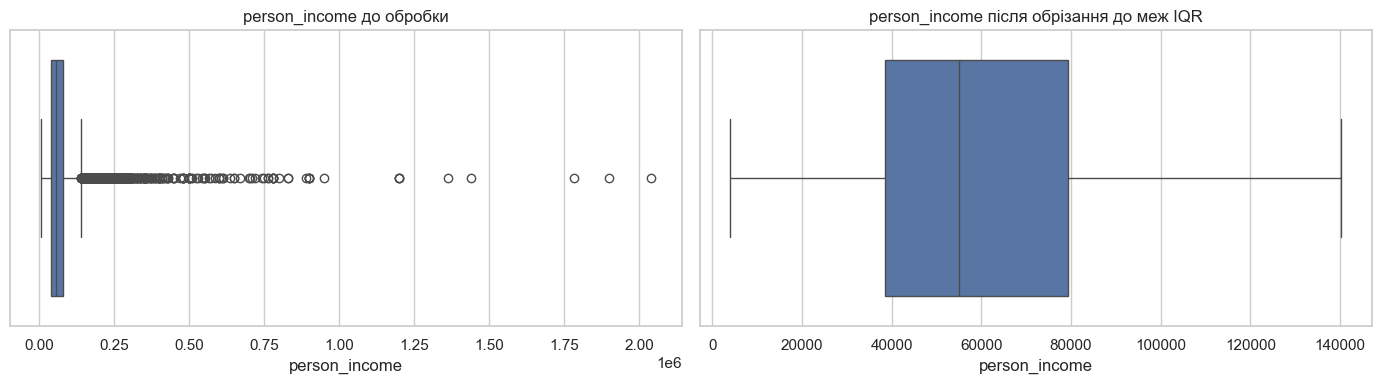

In [8]:
q1 = df['person_income'].quantile(0.25)
q3 = df['person_income'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
is_outlier = (df['person_income'] < lower_bound) | (df['person_income'] > upper_bound)

print(f'Q1 = {q1:,.0f}, Q3 = {q3:,.0f}, IQR = {iqr:,.0f}')
print(f'Межі: від {lower_bound:,.0f} до {upper_bound:,.0f}')
print(f"Викидів: {is_outlier.sum()} ({is_outlier.mean():.1%}), максимальний дохід: {df['person_income'].max():,.0f}")
print(f"Частка дефолтів серед викидів: {df.loc[is_outlier, 'loan_status'].mean():.1%}, "
      f"серед решти: {df.loc[~is_outlier, 'loan_status'].mean():.1%}")

income_before = df['person_income'].copy()
df['person_income'] = df['person_income'].clip(lower=lower_bound, upper=upper_bound)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=income_before, ax=axes[0])
axes[0].set_title('person_income до обробки')
sns.boxplot(x=df['person_income'], ax=axes[1])
axes[1].set_title('person_income після обрізання до меж IQR')
plt.tight_layout()
plt.show()

In [9]:
for col in cat_cols:
    summary = df.groupby(col)['loan_status'].agg(['count', 'mean'])
    summary.columns = ['Кількість', 'Частка дефолтів']
    summary['Частка в даних'] = summary['Кількість'] / len(df)
    if col != 'loan_grade':
        summary = summary.sort_values('Частка дефолтів', ascending=False)
    print(col)
    display(summary.round(3))

person_home_ownership


,Кількість,Частка дефолтів,Частка в даних
person_home_ownership,,,
RENT,16374,0.316,0.505
OTHER,106,0.311,0.003
MORTGAGE,13366,0.126,0.412
OWN,2563,0.075,0.079


loan_intent


,Кількість,Частка дефолтів,Частка в даних
loan_intent,,,
DEBTCONSOLIDATION,5189,0.287,0.160
MEDICAL,6042,0.268,0.186
HOMEIMPROVEMENT,3594,0.262,0.111
PERSONAL,5496,0.199,0.170
EDUCATION,6409,0.173,0.198
VENTURE,5679,0.149,0.175


loan_grade


,Кількість,Частка дефолтів,Частка в даних
loan_grade,,,
A,10702,0.100,0.330
B,10384,0.163,0.320
C,6436,0.208,0.199
D,3619,0.590,0.112
E,963,0.645,0.030
F,241,0.705,0.007
G,64,0.984,0.002


cb_person_default_on_file


,Кількість,Частка дефолтів,Частка в даних
cb_person_default_on_file,,,
Y,5729,0.379,0.177
N,26680,0.184,0.823


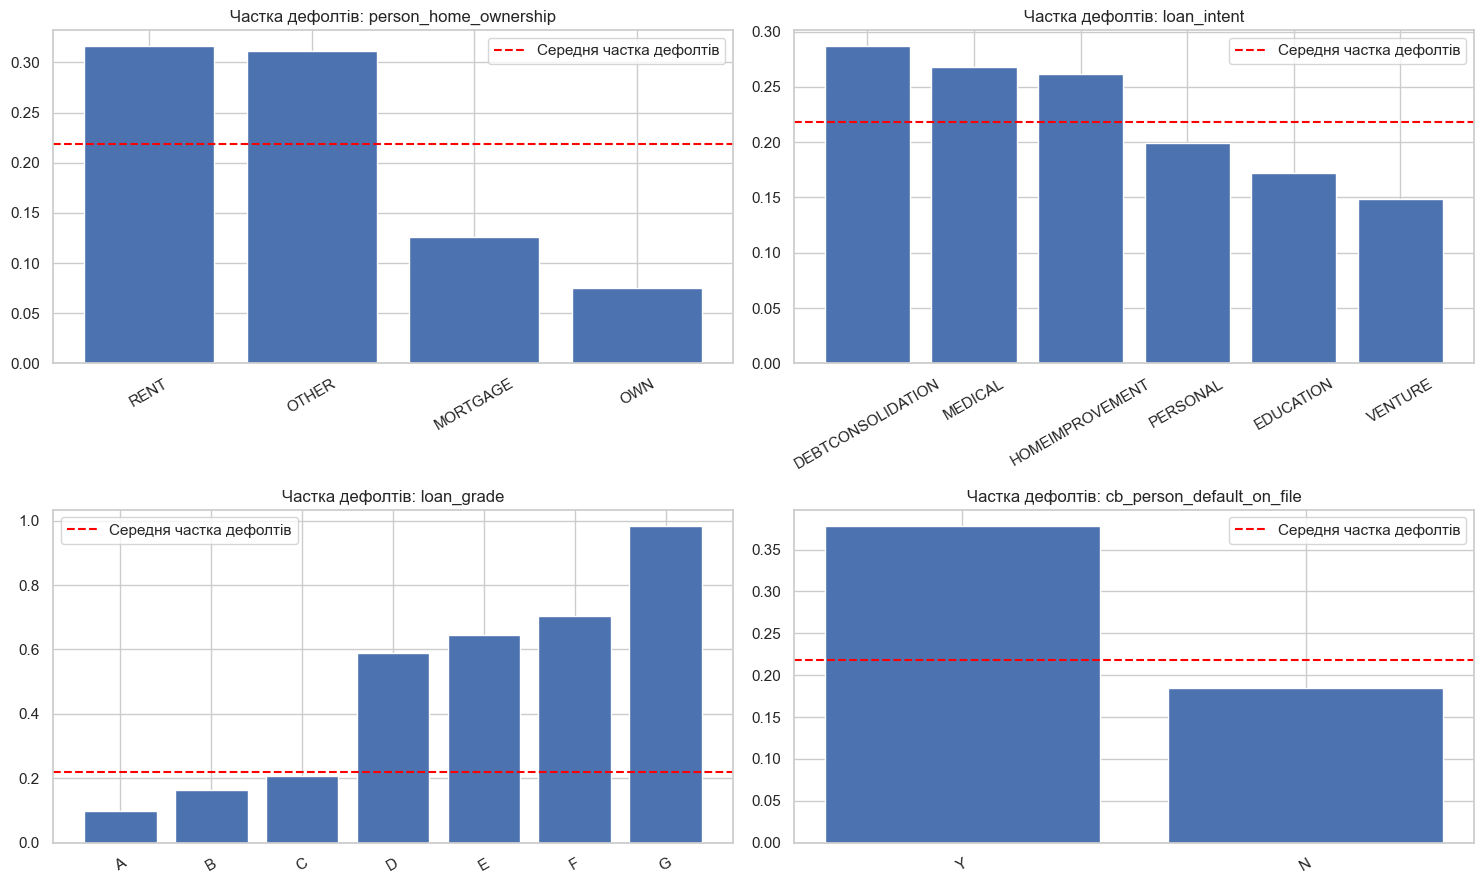

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flat, cat_cols):
    rate = df.groupby(col)['loan_status'].mean()
    rate = rate.sort_index() if col == 'loan_grade' else rate.sort_values(ascending=False)
    ax.bar(rate.index, rate.values, color='#4C72B0')
    ax.axhline(df['loan_status'].mean(), color='red', linestyle='--', label='Середня частка дефолтів')
    ax.set_title(f'Частка дефолтів: {col}')
    ax.tick_params(axis='x', rotation=30)
    ax.legend()
plt.tight_layout()
plt.show()

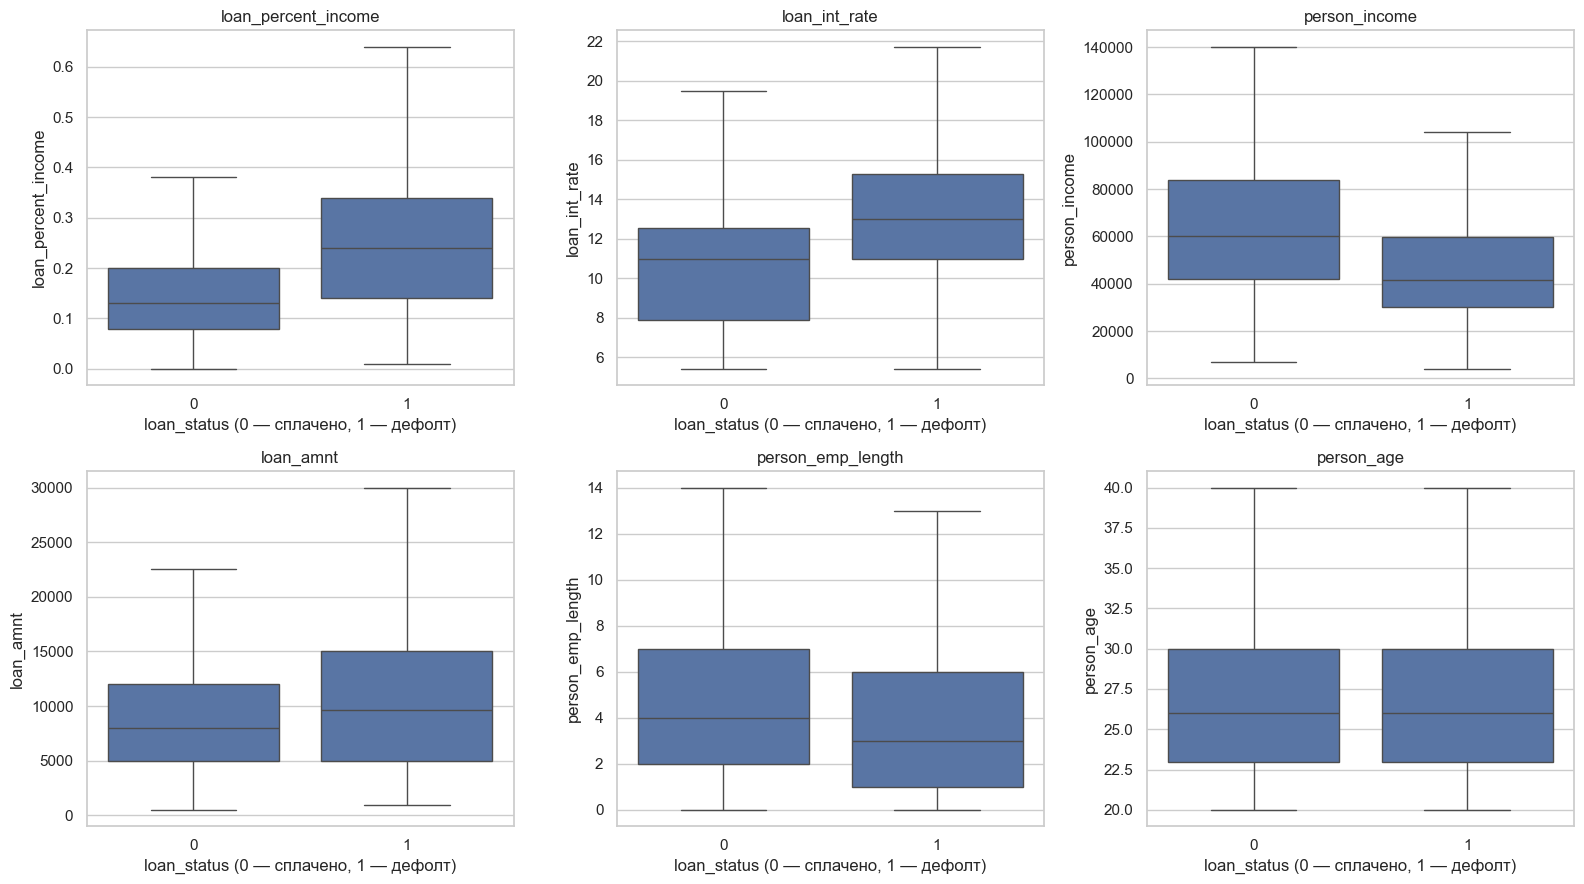

loan_status,0,1
person_age,26.00,26.00
person_income,60000.00,41655.00
person_emp_length,4.00,3.00
loan_amnt,8000.00,9600.00
loan_int_rate,10.99,12.99
loan_percent_income,0.13,0.24
cb_person_cred_hist_length,4.00,4.00


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, ['loan_percent_income', 'loan_int_rate', 'person_income',
                               'loan_amnt', 'person_emp_length', 'person_age']):
    sns.boxplot(data=df, x='loan_status', y=col, ax=ax, showfliers=False)
    ax.set_title(col)
    ax.set_xlabel('loan_status (0 — сплачено, 1 — дефолт)')
plt.tight_layout()
plt.show()

df.groupby('loan_status')[list(num_cols)].median().T.round(2)

**Висновки до EDA**

1. **Пропуски:** `loan_int_rate` — 9.6 %, `person_emp_length` — 2.7 %. Заповнили їх медіаною. У категоріальних колонках пропусків немає.
2. **Числові змінні.** Більшість позичальників молоді (медіана — 26 років). Дохід, сума кредиту і стаж скошені вправо. Є неправдоподібні значення: вік 144 роки, стаж 123 роки. Такі рядки (7) і повні дублікати (165) видалили — лишилось 32 409 рядків.
3. **Викиди в доході.** Верхня межа IQR ≈ 140 тис. Вище неї 1 474 позичальники (4.5 %), максимум — понад 2 млн. Ми не видаляли їх, а обрізали дохід до межі (capping). Так модель не втрачає заможних позичальників (серед них дефолтів лише 9.8 % проти 22.4 % у решти), а екстремальні значення не спотворюють коефіцієнти.
4. **Категоріальні змінні:**
   - `loan_grade` — найсильніший сигнал: частка дефолтів зростає з 10 % (A) до 59 % (D) і 98 % (G);
   - `person_home_ownership`: серед орендарів (RENT) 32 % дефолтів, серед власників житла (OWN) — 7.5 %; категорія OTHER рідкісна (близько 100 позичальників);
   - `loan_intent`: найризиковіші кредити — DEBTCONSOLIDATION (29 %), MEDICAL (27 %), HOMEIMPROVEMENT (26 %); найменш ризикові — VENTURE (15 %) і EDUCATION (17 %);
   - `cb_person_default_on_file`: з дефолтом в історії — 38 % дефолтів, без нього — 18 %.
5. **Числові ознаки і ціль.** У дефолтних кредитів помітно вищі `loan_percent_income` (частка кредиту в доході) і `loan_int_rate`, а дохід нижчий. Вік і стаж майже не відрізняються.


---

## Завдання 3: Аналіз кореляцій та Feature Engineering (3 бали)

**Що потрібно зробити:**
1. Побудуйте матрицю кореляцій для числових змінних.
2. Закодуйте категоріальні змінні.
3. Виберіть фінальний набір ознак, можна лишити всі, якщо ви вважаєте, що це - доцільно.



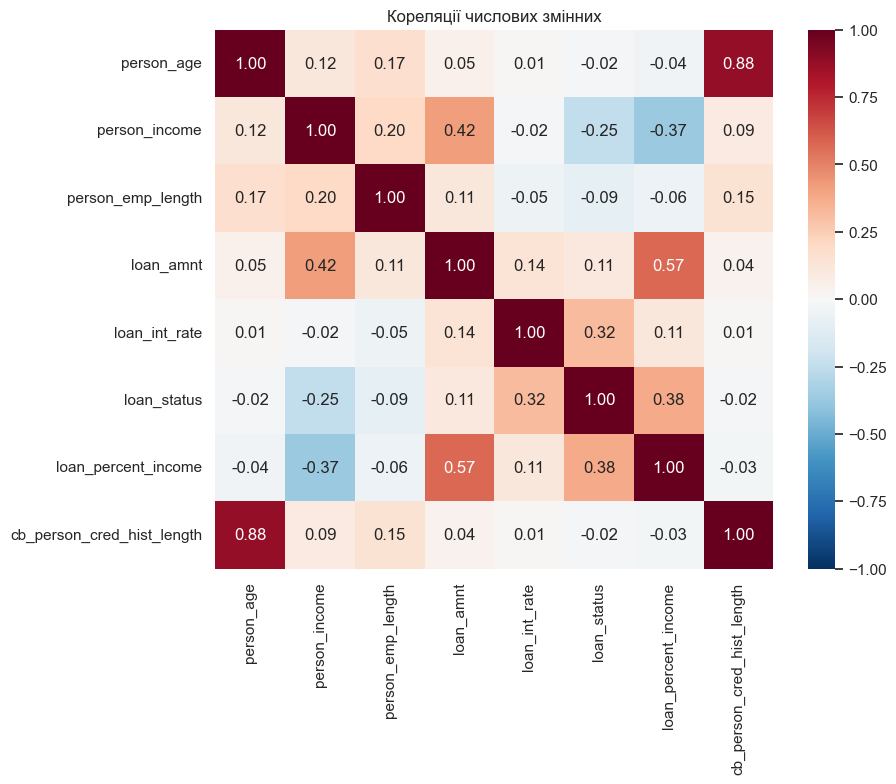

Найсильніші пари ознак:
person_age     cb_person_cred_hist_length    0.88
loan_amnt      loan_percent_income           0.57
person_income  loan_amnt                     0.42
               loan_percent_income          -0.37
dtype: float64


,Кореляція з loan_status
loan_percent_income,0.38
loan_int_rate,0.32
person_income,-0.25
loan_amnt,0.11
person_emp_length,-0.09
person_age,-0.02
cb_person_cred_hist_length,-0.02


In [12]:
corr = df.select_dtypes('number').corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Кореляції числових змінних')
plt.show()

pairs = corr.drop(index='loan_status', columns='loan_status')
pairs = pairs.where(np.triu(np.ones(pairs.shape, dtype=bool), k=1)).stack()
print('Найсильніші пари ознак:')
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(4).round(2))

corr['loan_status'].drop('loan_status').sort_values(key=np.abs, ascending=False).round(2).to_frame('Кореляція з loan_status')

In [13]:
df['loan_grade_num'] = df['loan_grade'].map({grade: i for i, grade in enumerate('ABCDEFG')})
df['cb_default_flag'] = (df['cb_person_default_on_file'] == 'Y').astype(int)
df_encoded = pd.get_dummies(df, columns=['person_home_ownership', 'loan_intent'], drop_first=True, dtype=int)
df_encoded = df_encoded.drop(columns=['loan_grade', 'cb_person_default_on_file'])
df_encoded.head()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length,loan_grade_num,cb_default_flag,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
1,21,9600,5.0,1000,11.14,0,0.10,2,1,0,0,1,0,1,0,0,0,0
2,25,9600,1.0,5500,12.87,1,0.57,3,2,0,0,0,0,0,0,1,0,0
3,23,65500,4.0,35000,15.23,1,0.53,2,2,0,0,0,1,0,0,1,0,0
4,24,54400,8.0,35000,14.27,1,0.55,4,2,1,0,0,1,0,0,1,0,0
5,21,9900,2.0,2500,7.14,1,0.25,2,0,0,0,1,0,0,0,0,0,1


In [14]:
features = [col for col in df_encoded.columns if col != 'loan_status']
print(f'Ознак: {len(features)}')
print(features)

Ознак: 17
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'loan_grade_num', 'cb_default_flag', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE']


**Висновки**

1. **Кореляції з ціллю.** Найсильніші — `loan_percent_income` (0.38), `loan_int_rate` (0.32) і дохід (−0.25: чим вищий дохід, тим менше дефолтів). Вік, стаж і довжина кредитної історії майже не корелюють з дефолтом.
2. **Кореляції між ознаками.** `person_age` і `cb_person_cred_hist_length` — 0.88: старші люди мають довшу кредитну історію. `loan_amnt` і `loan_percent_income` — 0.57.
3. **Кодування:**
   - `loan_grade` — порядкова ознака, тому закодували її числами 0–6: одна колонка зберігає порядок A < B < … < G;
   - `cb_person_default_on_file` → 0/1;
   - `person_home_ownership` і `loan_intent` не мають порядку → One-Hot з `drop_first=True`. Базові категорії — MORTGAGE і DEBTCONSOLIDATION.
4. **Фінальний набір.** Лишили всі 17 ознак. Логістична регресія в sklearn за замовчуванням має L2-регуляризацію: вона зменшує ваги слабких і корельованих ознак. Деревам у завданні 7 зайві ознаки теж не шкодять.


---

## Завдання 4: Підготовка даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на X та y
2. Поділіть на навчальну та тестову вибірки
3. Застосуйте масштабування
4. Навчіть модель логістичної регресії
5. Зробіть прогнози на тренувальній та тестовій вибірках.



In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X = df_encoded[features]
y = df_encoded['loan_status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f'Train: {X_train.shape[0]}, test: {X_test.shape[0]}')
print(f'Частка дефолтів: train {y_train.mean():.3f}, test {y_test.mean():.3f}')

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)
y_train_proba = model.predict_proba(X_train_scaled)[:, 1]
y_test_proba = model.predict_proba(X_test_scaled)[:, 1]

pd.DataFrame({
    'Реальний статус': y_test.values[:5],
    'Прогноз': y_test_pred[:5],
    'Ймовірність дефолту': y_test_proba[:5].round(3),
})

Train: 25927, test: 6482
Частка дефолтів: train 0.219, test 0.219


,Реальний статус,Прогноз,Ймовірність дефолту
0,0,0,0.237
1,1,0,0.185
2,0,0,0.420
3,0,0,0.201
4,1,1,0.763


Модель навчена на 80 % даних. Scaler навчали лише на train, щоб інформація з тестової вибірки не «протекла» в модель. Для кожного позичальника модель дає ймовірність дефолту. Клас 1 вона ставить, коли ця ймовірність ≥ 0.5.


---

## Завдання 5: Оцінка якості моделі (4 бали)

**Що потрібно зробити:**
1. Побудуйте confusion matrix.
2. Обчисліть основні метрики (accuracy, precision, recall, f1).
3. Побудуйте ROC-криву та обчисліть AUC
4. Проаналізуйте важливість ознак.
5. Зробіть висновки про якість моделі та які ознаки найбільше впливають на прогноз.


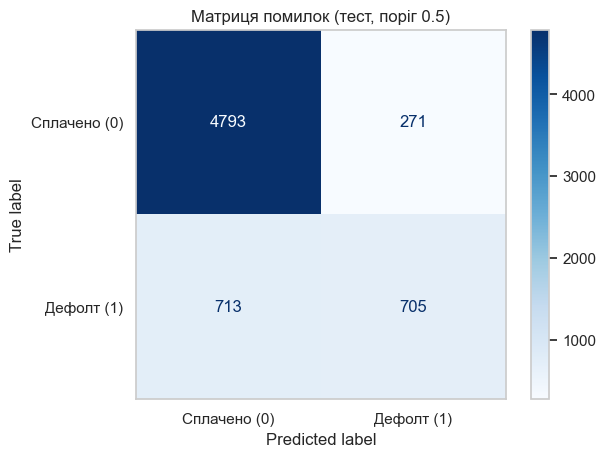

TN = 4793, FP = 271, FN = 713, TP = 705


In [16]:
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)

cm = confusion_matrix(y_test, y_test_pred)
ConfusionMatrixDisplay(cm, display_labels=['Сплачено (0)', 'Дефолт (1)']).plot(cmap='Blues', values_format='d')
plt.title('Матриця помилок (тест, поріг 0.5)')
plt.grid(False)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}')

In [17]:
def classification_metrics(y_true, y_pred, y_proba):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
        'roc_auc': roc_auc_score(y_true, y_proba),
    }

pd.DataFrame({
    'Train': classification_metrics(y_train, y_train_pred, y_train_proba),
    'Test': classification_metrics(y_test, y_test_pred, y_test_proba),
}).T.round(3)

,accuracy,precision,recall,f1,roc_auc
Train,0.855,0.742,0.513,0.607,0.864
Test,0.848,0.722,0.497,0.589,0.864


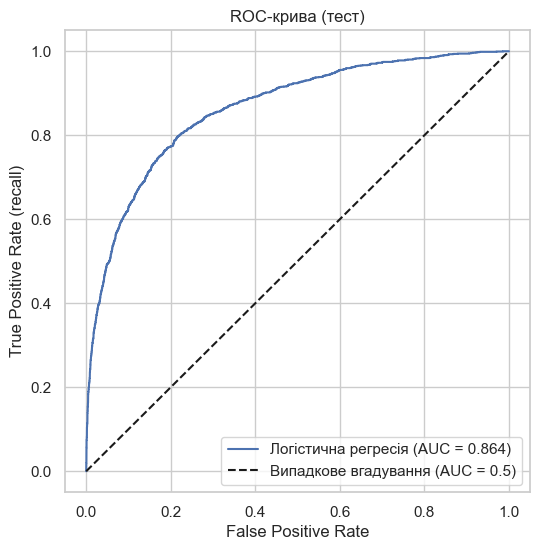

In [18]:
fpr, tpr, _ = roc_curve(y_test, y_test_proba)
auc = roc_auc_score(y_test, y_test_proba)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Логістична регресія (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Випадкове вгадування (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (recall)')
plt.title('ROC-крива (тест)')
plt.legend()
plt.show()

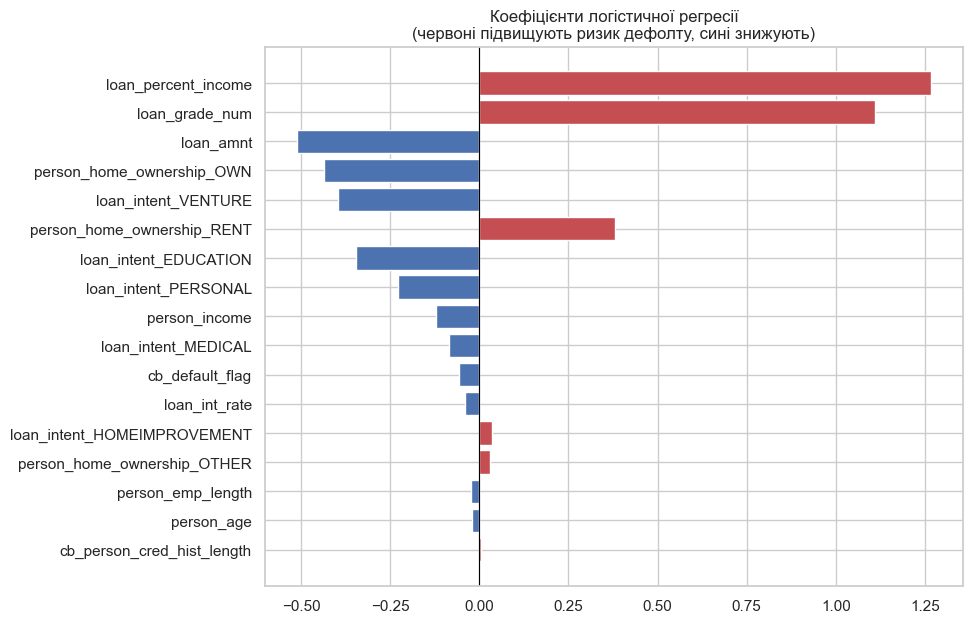

,Ознака,Коефіцієнт
0,loan_percent_income,1.267
1,loan_grade_num,1.111
2,loan_amnt,-0.512
3,person_home_ownership_OWN,-0.435
4,loan_intent_VENTURE,-0.396
5,person_home_ownership_RENT,0.380
6,loan_intent_EDUCATION,-0.345
7,loan_intent_PERSONAL,-0.229
8,person_income,-0.121
9,loan_intent_MEDICAL,-0.086


In [19]:
importance = pd.DataFrame({'Ознака': features, 'Коефіцієнт': model.coef_[0]})
importance = importance.reindex(importance['Коефіцієнт'].abs().sort_values(ascending=False).index)

plt.figure(figsize=(9, 7))
colors = np.where(importance['Коефіцієнт'] > 0, '#C44E52', '#4C72B0')
plt.barh(importance['Ознака'], importance['Коефіцієнт'], color=colors)
plt.gca().invert_yaxis()
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Коефіцієнти логістичної регресії\n(червоні підвищують ризик дефолту, сині знижують)')
plt.show()

importance.round(3).reset_index(drop=True)

**Висновки про якість моделі**

1. **Матриця помилок (поріг 0.5).** З 1 418 дефолтів у тесті модель знайшла 705 (TP) і пропустила 713 (FN). Сумлінних позичальників помилково позначила ризиковими лише 271 (FP).
2. **Метрики на тесті:** accuracy ≈ 0.848, precision ≈ 0.722, recall ≈ 0.497, F1 ≈ 0.589, ROC AUC ≈ 0.864.
   - Accuracy лише помірно краща за модель «завжди сплатить» (0.78).
   - Precision 0.72: коли модель каже «дефолт», вона права приблизно в 72 % випадків.
   - Recall 0.50: модель знаходить лише половину реальних дефолтів. Для банку це головна слабкість.
   - AUC 0.86: модель добре ранжує позичальників за ризиком. Отже, recall можна підняти, якщо знизити поріг (завдання 6).
3. **Перенавчання немає:** метрики на train і test майже однакові.
4. **Які ознаки найбільше впливають на прогноз:**
   - `loan_percent_income` (+) — найсильніша ознака: чим більша частка кредиту в доході, тим вищий ризик;
   - `loan_grade_num` (+): гірший кредитний рейтинг — вищий ризик;
   - `loan_amnt` (−): знак відʼємний, бо модель уже врахувала частку кредиту в доході. За однакової частки більша сума означає вищий дохід;
   - `person_home_ownership_RENT` (+) і `person_home_ownership_OWN` (−): орендарі ризиковіші, власники житла — найменш ризикові;
   - `loan_intent_VENTURE` і `loan_intent_EDUCATION` (−): ці цілі кредиту менш ризикові, ніж консолідація боргів (базова категорія).

   `cb_default_flag` і `loan_int_rate` мають малі коефіцієнти: їхню інформацію вже несе `loan_grade_num`.


---

## Завдання 6: Оптимізація порогу та бізнес-аналіз (2 бали)

**Що потрібно зробити:**
1. Проаналізуйте метрики precision, recall, F1 при різних порогах класифікації (мінімум - 5 різних порогів). Візуалізуйте як змінюються метрики якості при зміні порогу.
2. Оберіть оптимальний поріг для бізнес-задачі - можна обрати виходячи з попереднього пункту, або додати своїх роздумів і обрати інший.



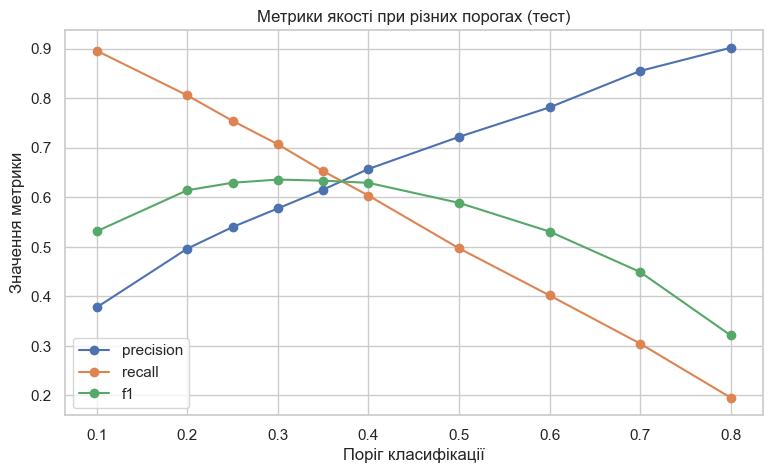

,Поріг,precision,recall,f1,"Частка заявок, позначених як дефолт"
0,0.10,0.378,0.896,0.532,0.519
1,0.20,0.497,0.806,0.615,0.355
2,0.25,0.540,0.755,0.630,0.306
3,0.30,0.578,0.707,0.636,0.268
4,0.35,0.616,0.653,0.634,0.232
5,0.40,0.657,0.604,0.629,0.201
6,0.50,0.722,0.497,0.589,0.151
7,0.60,0.782,0.402,0.531,0.112
8,0.70,0.855,0.305,0.449,0.078
9,0.80,0.902,0.195,0.321,0.047


In [20]:
thresholds = [0.1, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6, 0.7, 0.8]
rows = []
for t in thresholds:
    pred_t = (y_test_proba >= t).astype(int)
    rows.append({
        'Поріг': t,
        'precision': precision_score(y_test, pred_t),
        'recall': recall_score(y_test, pred_t),
        'f1': f1_score(y_test, pred_t),
        'Частка заявок, позначених як дефолт': pred_t.mean(),
    })
threshold_df = pd.DataFrame(rows)

plt.figure(figsize=(9, 5))
for metric in ['precision', 'recall', 'f1']:
    plt.plot(threshold_df['Поріг'], threshold_df[metric], marker='o', label=metric)
plt.xlabel('Поріг класифікації')
plt.ylabel('Значення метрики')
plt.title('Метрики якості при різних порогах (тест)')
plt.legend()
plt.show()

threshold_df.round(3)

Найменші втрати — при порозі 0.40: 5,363,036
При стандартному порозі 0.5: 5,595,126


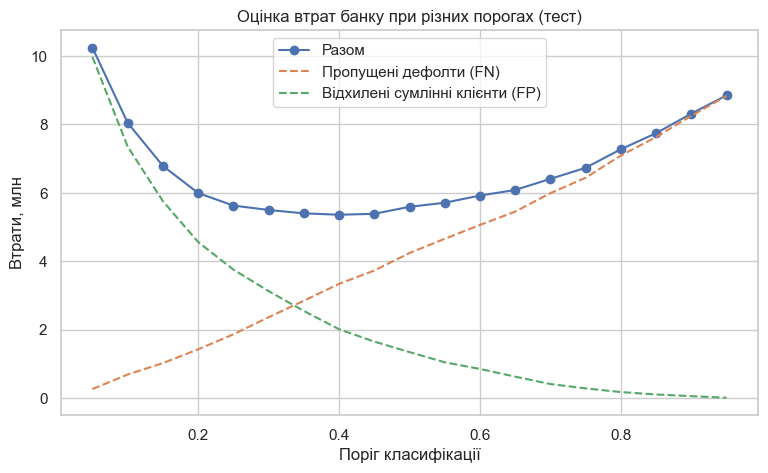

,Поріг,Втрати від FN,Втрати від FP,Разом,"Різниця з порогом 0.5, %"
4,0.25,1870125.0,3761193.0,5631318.0,0.6
5,0.30,2369625.0,3132548.0,5502173.0,-1.7
6,0.35,2850675.0,2553653.0,5404328.0,-3.4
7,0.40,3343920.0,2019116.0,5363036.0,-4.1
8,0.45,3733725.0,1657145.0,5390870.0,-3.7
9,0.50,4244805.0,1350321.0,5595126.0,0.0
10,0.55,4661160.0,1052630.0,5713790.0,2.1


In [21]:
LOSS_GIVEN_DEFAULT = 0.6
LOAN_TERM_YEARS = 3

amount = X_test['loan_amnt'].to_numpy()
rate = X_test['loan_int_rate'].to_numpy() / 100
y_true = y_test.to_numpy()
grid = np.round(np.arange(0.05, 0.96, 0.05), 2)

def bank_losses(threshold, lgd=LOSS_GIVEN_DEFAULT, years=LOAN_TERM_YEARS):
    flagged = y_test_proba >= threshold
    fn_loss = (amount * lgd)[(y_true == 1) & ~flagged].sum()
    fp_loss = (amount * rate * years)[(y_true == 0) & flagged].sum()
    return fn_loss, fp_loss

cost_df = pd.DataFrame([(t, *bank_losses(t)) for t in grid], columns=['Поріг', 'Втрати від FN', 'Втрати від FP'])
cost_df['Разом'] = cost_df['Втрати від FN'] + cost_df['Втрати від FP']

best_row = cost_df.loc[cost_df['Разом'].idxmin()]
loss_05 = cost_df.loc[cost_df['Поріг'] == 0.5, 'Разом'].iloc[0]
print(f"Найменші втрати — при порозі {best_row['Поріг']:.2f}: {best_row['Разом']:,.0f}")
print(f"При стандартному порозі 0.5: {loss_05:,.0f}")

plt.figure(figsize=(9, 5))
plt.plot(cost_df['Поріг'], cost_df['Разом'] / 1e6, marker='o', label='Разом')
plt.plot(cost_df['Поріг'], cost_df['Втрати від FN'] / 1e6, '--', label='Пропущені дефолти (FN)')
plt.plot(cost_df['Поріг'], cost_df['Втрати від FP'] / 1e6, '--', label='Відхилені сумлінні клієнти (FP)')
plt.xlabel('Поріг класифікації')
plt.ylabel('Втрати, млн')
plt.title('Оцінка втрат банку при різних порогах (тест)')
plt.legend()
plt.show()

near_min = cost_df[(cost_df['Поріг'] >= 0.25) & (cost_df['Поріг'] <= 0.55)].copy()
near_min['Різниця з порогом 0.5, %'] = (near_min['Разом'] / loss_05 - 1) * 100
near_min.round({'Втрати від FN': 0, 'Втрати від FP': 0, 'Разом': 0, 'Різниця з порогом 0.5, %': 1})

In [22]:
def best_threshold_for(lgd, years):
    totals = [sum(bank_losses(t, lgd, years)) for t in grid]
    return grid[int(np.argmin(totals))]

lgd_values = [0.4, 0.6, 0.8, 1.0]
pd.DataFrame(
    {f'Кредит на {years} р.': [best_threshold_for(lgd, years) for lgd in lgd_values] for years in (1, 3, 5)},
    index=[f'Банк втрачає {lgd:.0%} суми дефолту' for lgd in lgd_values],
)

,Кредит на 1 р.,Кредит на 3 р.,Кредит на 5 р.
Банк втрачає 40% суми дефолту,0.20,0.45,0.65
Банк втрачає 60% суми дефолту,0.15,0.40,0.55
Банк втрачає 80% суми дефолту,0.15,0.25,0.45
Банк втрачає 100% суми дефолту,0.10,0.25,0.40


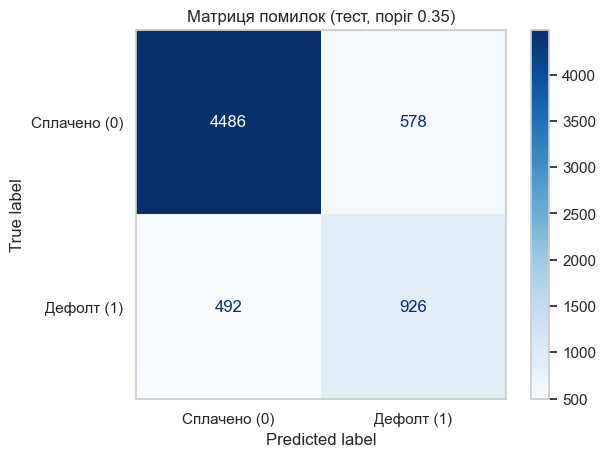

Поріг 0.35: TN = 4486, FP = 578, FN = 492, TP = 926
Порівняно з порогом 0.5: знайдено дефолтів більше на 221, хибних тривог більше на 307


,accuracy,precision,recall,f1,roc_auc
Поріг 0.5,0.848,0.722,0.497,0.589,0.864
Поріг 0.35,0.835,0.616,0.653,0.634,0.864


In [23]:
best_threshold = 0.35
y_test_pred_best = (y_test_proba >= best_threshold).astype(int)
cm_best = confusion_matrix(y_test, y_test_pred_best)

ConfusionMatrixDisplay(cm_best, display_labels=['Сплачено (0)', 'Дефолт (1)']).plot(cmap='Blues', values_format='d')
plt.title(f'Матриця помилок (тест, поріг {best_threshold})')
plt.grid(False)
plt.show()

tn_b, fp_b, fn_b, tp_b = cm_best.ravel()
print(f'Поріг {best_threshold}: TN = {tn_b}, FP = {fp_b}, FN = {fn_b}, TP = {tp_b}')
print(f'Порівняно з порогом 0.5: знайдено дефолтів більше на {tp_b - tp}, хибних тривог більше на {fp_b - fp}')

pd.DataFrame({
    'Поріг 0.5': classification_metrics(y_test, y_test_pred, y_test_proba),
    f'Поріг {best_threshold}': classification_metrics(y_test, y_test_pred_best, y_test_proba),
}).T.round(3)

**Висновки до завдання 6**

1. **Як поріг змінює метрики.** Зі зниженням порогу recall зростає, а precision падає. Модель частіше каже «дефолт»: знаходить більше реальних дефолтів, але й частіше помиляється щодо сумлінних клієнтів. F1 найвищий у діапазоні порогів 0.25–0.40 (максимум 0.636 при порозі 0.3).
2. **Що важливіше для банку.** Пропущений дефолт (FN) коштує банку значної частини суми кредиту. Відхилений сумлінний клієнт (FP) коштує лише втрачених відсотків. Тому FN дорожчі за FP, і поріг варто знизити від стандартного 0.5.
3. **Оцінка втрат.** За базових припущень (банк втрачає 60 % суми дефолтного кредиту, кредит видається на 3 роки) найменші втрати — при порозі 0.40. Але біля мінімуму крива пласка: пороги 0.30–0.45 дають майже однакові втрати. Таблиця чутливості показує, що найкращий поріг сильно залежить від припущень — від 0.10 до 0.65. Тож реальні цифри втрат варто взяти в ризик-менеджменту банку.
4. **Обраний поріг — 0.35.** Він лежить у «пласкій» зоні обох критеріїв: F1 майже максимальний (0.634 проти 0.636), а втрати менш ніж на 1 % більші за мінімум. Порівняно з порогом 0.5:
   - recall зростає з 0.50 до 0.65 — модель знаходить на 221 дефолт більше;
   - precision падає з 0.72 до 0.62 — хибних тривог більше на 307;
   - частка заявок, позначених як ризикові, зростає з 15 % до 23 %;
   - за нашими припущеннями втрати банку менші приблизно на 3.4 %.


---

## Завдання 7 (Опціональне): Покращення моделі та висновки (2 бали)

**Що потрібно зробити:**

На цих же даних навчіть DecisionTreeClassifier та RandomForestClassifier. Яка з трьох моделей дає найкращий результат на тестовому наборі?

Поріг класифікації можна для порівняння якостей моделей використовувати стандартний 0.5, або той, що ви виявили, як оптимальний на попередньому кроці.


In [24]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

tree = DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=42)
forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)
tree.fit(X_train, y_train)
forest.fit(X_train, y_train)

models = {
    'Логістична регресія': (y_train_proba, y_test_proba),
    'Decision Tree': (tree.predict_proba(X_train)[:, 1], tree.predict_proba(X_test)[:, 1]),
    'Random Forest': (forest.predict_proba(X_train)[:, 1], forest.predict_proba(X_test)[:, 1]),
}

rows = []
for name, (proba_train, proba_test) in models.items():
    row = classification_metrics(y_test, (proba_test >= 0.5).astype(int), proba_test)
    row['roc_auc (train)'] = roc_auc_score(y_train, proba_train)
    rows.append(pd.Series(row, name=name))
pd.DataFrame(rows).round(3)

,accuracy,precision,recall,f1,roc_auc,roc_auc (train)
Логістична регресія,0.848,0.722,0.497,0.589,0.864,0.864
Decision Tree,0.926,0.947,0.700,0.805,0.917,0.923
Random Forest,0.935,0.972,0.725,0.830,0.937,1.000


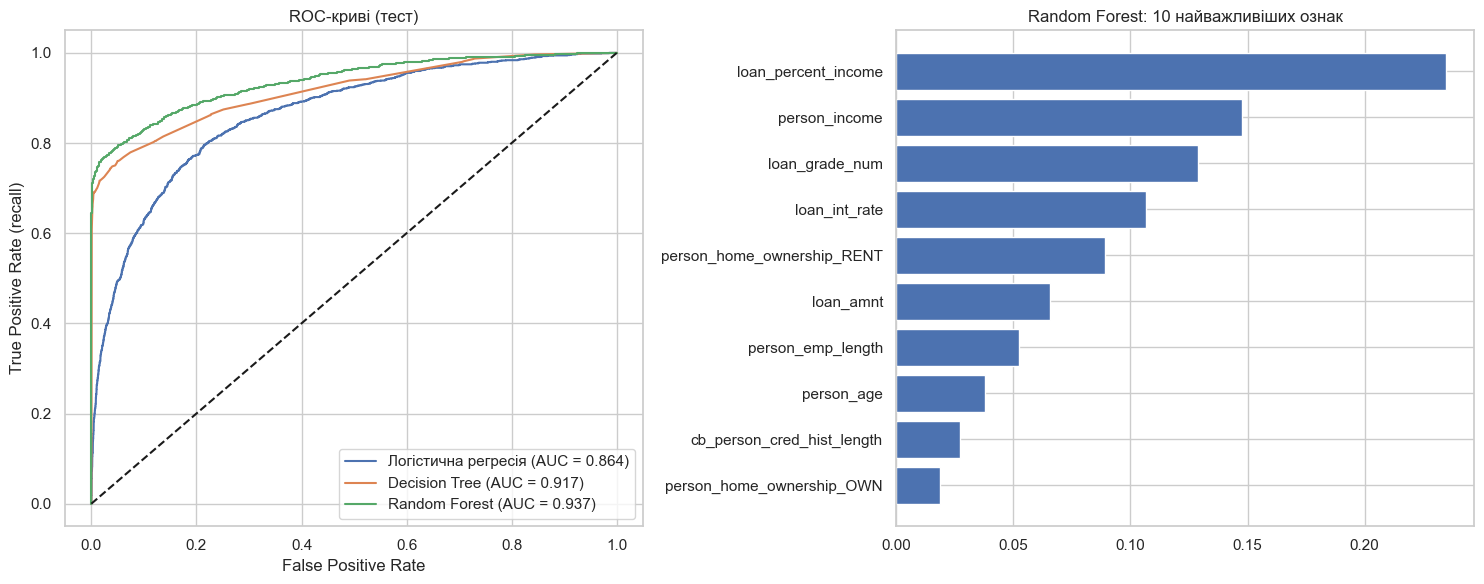

Найважливіші ознаки Random Forest:
loan_percent_income           0.235
person_income                 0.148
loan_grade_num                0.129
loan_int_rate                 0.107
person_home_ownership_RENT    0.089
dtype: float64


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, (_, proba_test) in models.items():
    fpr_m, tpr_m, _ = roc_curve(y_test, proba_test)
    axes[0].plot(fpr_m, tpr_m, label=f'{name} (AUC = {roc_auc_score(y_test, proba_test):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (recall)')
axes[0].set_title('ROC-криві (тест)')
axes[0].legend()

forest_importance = pd.Series(forest.feature_importances_, index=features).sort_values().tail(10)
axes[1].barh(forest_importance.index, forest_importance.values, color='#4C72B0')
axes[1].set_title('Random Forest: 10 найважливіших ознак')
plt.tight_layout()
plt.show()

print('Найважливіші ознаки Random Forest:')
print(forest_importance.sort_values(ascending=False).head(5).round(3))

**Висновок до завдання 7**

**Найкращий результат на тестовій вибірці дає Random Forest** — за всіма метриками: accuracy 0.935, precision 0.972, recall 0.725, F1 0.830, ROC AUC 0.937. Decision Tree трохи слабший (F1 0.805, AUC 0.917). Логістична регресія — найслабша (F1 0.589, AUC 0.864).

**Чому дерева кращі.** Ризик дефолту залежить від ознак нелінійно. Логістична регресія має для кожної ознаки одну вагу, а дерева ділять позичальників на групи з різними правилами. Наприклад, дерево може знайти поріг частки кредиту в доході, після якого ризик різко зростає. Для Random Forest найважливіші ознаки — `loan_percent_income`, `person_income`, `loan_grade_num`, `loan_int_rate` і `person_home_ownership_RENT`.

**Застереження.** На train у Random Forest ROC AUC = 1.000: ліс «запамʼятовує» навчальні дані. На тесті він усе одно найкращий, але перед використанням варто налаштувати гіперпараметри (глибину дерев, мінімальний розмір листка) з крос-валідацією. Також для лісу варто окремо підібрати поріг, як у завданні 6: при порозі 0.5 він ще пропускає чверть дефолтів (recall 0.725).